In [3]:
%pylab inline
import seaborn; seaborn.set_style('whitegrid')
import itertools

from avocado.model import Avocado

Populating the interactive namespace from numpy and matplotlib


## Avocado Demo

This tutorial will serve as a demonstration of how to use the Avocado code to learn a latent representation from epigenomic experiments. The use of such a trained model in two fold: firstly, one can use it to impute epigenomic experiments that it was not trained on, and secondly, one can use the extracted latent factors in downstream genomics tasks.

In [21]:
celltypes = ['E003', 'E017', 'E065', 'E116', 'E117']
assays = ['H3K4me3', 'H3K27me3', 'H3K36me3', 'H3K9me3', 'H3K4me1']

data = {}
for celltype, assay in itertools.product(celltypes, assays):
    if celltype == 'E065' and assay == 'H3K4me3':
        continue
        
    filename = 'data/{}.{}.pilot.arcsinh.npz'.format(celltype, assay)
    data[(celltype, assay)] = numpy.load(filename)['arr_0']


model = Avocado(celltypes, assays, n_layers=1, n_nodes=128, n_assay_factors=32,
        n_25bp_factors=10, n_250bp_factors=20, n_5kbp_factors=30, batch_size=10000)
model.fit(data, n_epochs=1)

Epoch 1/1
120/120 [==============================] - 25s 212ms/step - loss: 0.2374 - mean_squared_error: 0.2374


In [22]:
y_true = numpy.load("data/E003.H3K4me3.pilot.arcsinh.npz")['arr_0']
y_hat  = model.predict("E065", "H3K4me3")

print ((y_hat - y_true) ** 2).mean(), ((y_true - y_true.mean()) ** 2).mean()

0.34242883 0.34228426


(5000, 20000)

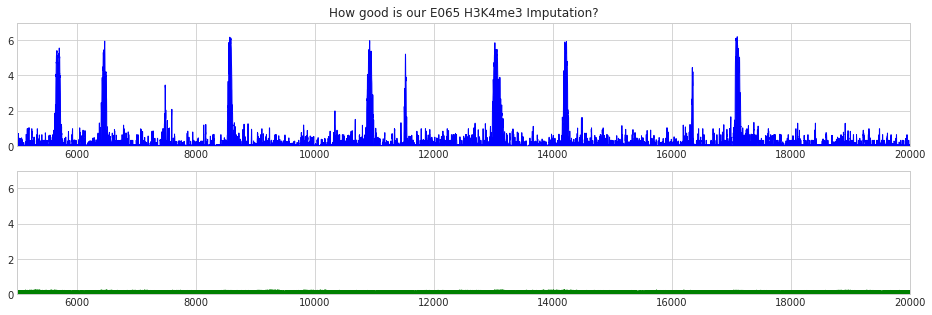

In [23]:
start, end = 12750, 14500
start, end = 5000, 20000
x = numpy.arange(start, end)

plt.figure(figsize=(16, 5))
plt.subplot(211)
plt.title("How good is our E065 H3K4me3 Imputation?")
plt.fill_between(x, 0, y_true[start:end], color='b')
plt.ylim(0, 7)
plt.xlim(start, end)

plt.subplot(212)
plt.fill_between(x, 0, y_hat[start:end], color='g')
plt.ylim(0, 7)
plt.xlim(start, end)

In [24]:
model.fit(data, n_epochs=1)

Epoch 1/1
120/120 [==============================] - 23s 196ms/step - loss: 0.2292 - mean_squared_error: 0.2292


In [25]:
y_true = numpy.load("data/E003.H3K4me3.pilot.arcsinh.npz")['arr_0']
y_hat  = model.predict("E065", "H3K4me3")

print ((y_hat - y_true) ** 2).mean(), ((y_true - y_true.mean()) ** 2).mean()

0.3243915 0.34228426


(12750, 14500)

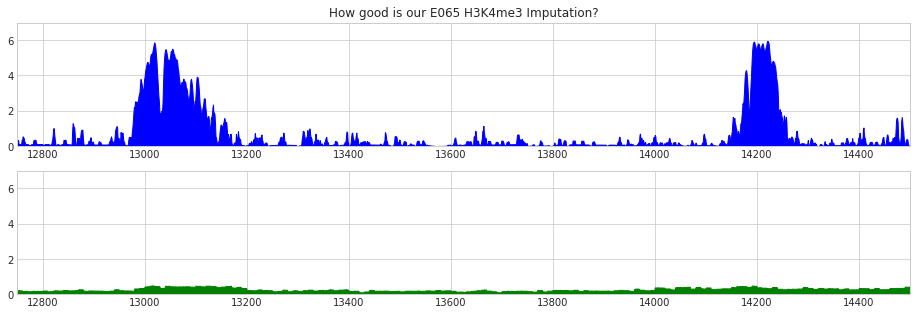

In [27]:
start, end = 12750, 14500
x = numpy.arange(start, end)

plt.figure(figsize=(16, 5))
plt.subplot(211)
plt.title("How good is our E065 H3K4me3 Imputation?")
plt.fill_between(x, 0, y_true[start:end], color='b')
plt.ylim(0, 7)
plt.xlim(start, end)

plt.subplot(212)
plt.fill_between(x, 0, y_hat[start:end], color='g')
plt.ylim(0, 7)
plt.xlim(start, end)

In [28]:
model.fit(data, n_epochs=3)

avocado/model.py:135: UserWarning: Update your `fit_generator` call to the Keras 2 API: `fit_generator(<generator..., 120, 3, workers=1, use_multiprocessing=True)`
  self.model.fit_generator(X_train_gen, epoch_size, n_epochs, workers=1, pickle_safe=True)


Epoch 1/3
120/120 [==============================] - 21s 173ms/step - loss: 0.2204 - mean_squared_error: 0.2204
Epoch 2/3
120/120 [==============================] - 20s 169ms/step - loss: 0.2070 - mean_squared_error: 0.2070
Epoch 3/3
120/120 [==============================] - 22s 182ms/step - loss: 0.2043 - mean_squared_error: 0.2043


In [29]:
y_true = numpy.load("data/E003.H3K4me3.pilot.arcsinh.npz")['arr_0']
y_hat  = model.predict("E065", "H3K4me3")

print ((y_hat - y_true) ** 2).mean(), ((y_true - y_true.mean()) ** 2).mean()

0.2735588 0.34228426


(12750, 14500)

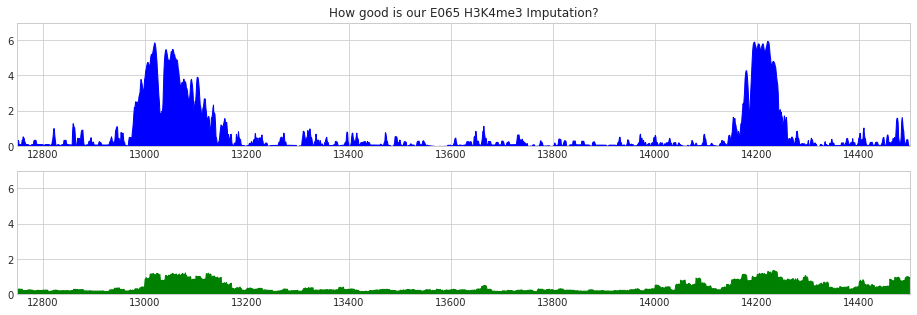

In [30]:
start, end = 12750, 14500
x = numpy.arange(start, end)

plt.figure(figsize=(16, 5))
plt.subplot(211)
plt.title("How good is our E065 H3K4me3 Imputation?")
plt.fill_between(x, 0, y_true[start:end], color='b')
plt.ylim(0, 7)
plt.xlim(start, end)

plt.subplot(212)
plt.fill_between(x, 0, y_hat[start:end], color='g')
plt.ylim(0, 7)
plt.xlim(start, end)

In [31]:
model.fit(data, n_epochs=5)

avocado/model.py:135: UserWarning: Update your `fit_generator` call to the Keras 2 API: `fit_generator(<generator..., 120, 5, workers=1, use_multiprocessing=True)`
  self.model.fit_generator(X_train_gen, epoch_size, n_epochs, workers=1, pickle_safe=True)


Epoch 1/5
120/120 [==============================] - 20s 171ms/step - loss: 0.1824 - mean_squared_error: 0.1824
Epoch 2/5
120/120 [==============================] - 20s 170ms/step - loss: 0.1619 - mean_squared_error: 0.1619
Epoch 3/5
120/120 [==============================] - 21s 171ms/step - loss: 0.1571 - mean_squared_error: 0.1571
Epoch 4/5
120/120 [==============================] - 21s 176ms/step - loss: 0.1495 - mean_squared_error: 0.1495
Epoch 5/5
120/120 [==============================] - 20s 169ms/step - loss: 0.1343 - mean_squared_error: 0.1343


0.19504295 0.34228426


(12750, 14500)

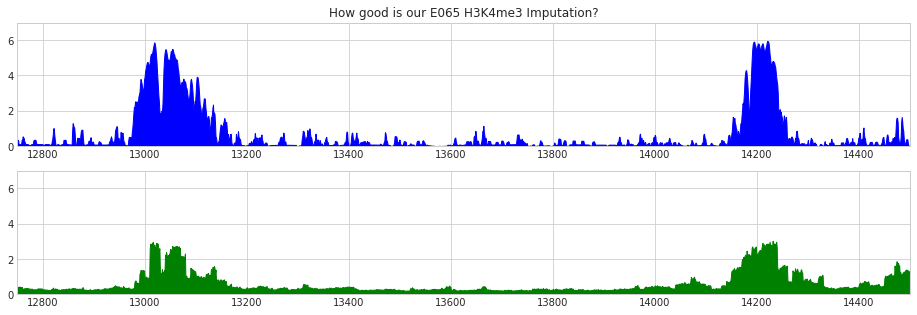

In [33]:
y_true = numpy.load("data/E003.H3K4me3.pilot.arcsinh.npz")['arr_0']
y_hat  = model.predict("E065", "H3K4me3")

print ((y_hat - y_true) ** 2).mean(), ((y_true - y_true.mean()) ** 2).mean()

start, end = 12750, 14500
x = numpy.arange(start, end)

plt.figure(figsize=(16, 5))
plt.subplot(211)
plt.title("How good is our E065 H3K4me3 Imputation?")
plt.fill_between(x, 0, y_true[start:end], color='b')
plt.ylim(0, 7)
plt.xlim(start, end)

plt.subplot(212)
plt.fill_between(x, 0, y_hat[start:end], color='g')
plt.ylim(0, 7)
plt.xlim(start, end)

In [34]:
model.fit(data, n_epochs=10)

Epoch 1/10
120/120 [==============================] - 21s 172ms/step - loss: 0.1316 - mean_squared_error: 0.1316
Epoch 2/10
120/120 [==============================] - 24s 199ms/step - loss: 0.1221 - mean_squared_error: 0.1221
Epoch 3/10
120/120 [==============================] - 20s 168ms/step - loss: 0.1218 - mean_squared_error: 0.1218
Epoch 4/10
120/120 [==============================] - 21s 174ms/step - loss: 0.1175 - mean_squared_error: 0.1175
Epoch 5/10
120/120 [==============================] - 20s 169ms/step - loss: 0.1100 - mean_squared_error: 0.1100
Epoch 6/10
120/120 [==============================] - 21s 174ms/step - loss: 0.1083 - mean_squared_error: 0.1083
Epoch 7/10
120/120 [==============================] - 20s 171ms/step - loss: 0.1037 - mean_squared_error: 0.1037
Epoch 8/10
120/120 [==============================] - 21s 176ms/step - loss: 0.1021 - mean_squared_error: 0.1021
Epoch 9/10
120/120 [==============================] - 22s 180ms/step - loss: 0.0980 - mean_squar

0.2187602 0.34228426


(12750, 14500)

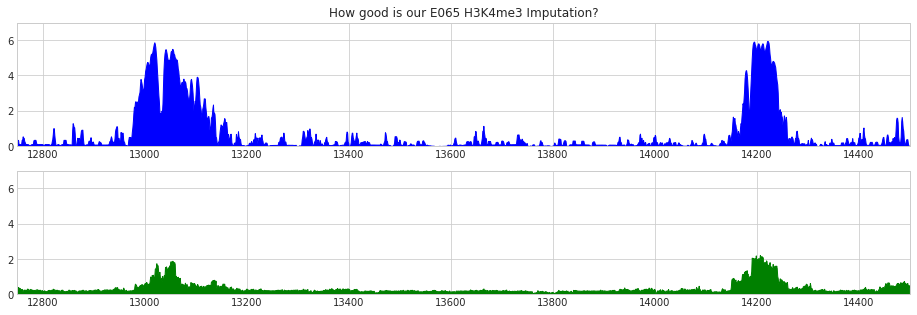

In [35]:
y_true = numpy.load("data/E003.H3K4me3.pilot.arcsinh.npz")['arr_0']
y_hat  = model.predict("E065", "H3K4me3")

print ((y_hat - y_true) ** 2).mean(), ((y_true - y_true.mean()) ** 2).mean()

start, end = 12750, 14500
x = numpy.arange(start, end)

plt.figure(figsize=(16, 5))
plt.subplot(211)
plt.title("How good is our E065 H3K4me3 Imputation?")
plt.fill_between(x, 0, y_true[start:end], color='b')
plt.ylim(0, 7)
plt.xlim(start, end)

plt.subplot(212)
plt.fill_between(x, 0, y_hat[start:end], color='g')
plt.ylim(0, 7)
plt.xlim(start, end)

In [36]:
model.fit(data, n_epochs=20)

avocado/model.py:135: UserWarning: Update your `fit_generator` call to the Keras 2 API: `fit_generator(<generator..., 120, 20, workers=1, use_multiprocessing=True)`
  self.model.fit_generator(X_train_gen, epoch_size, n_epochs, workers=1, pickle_safe=True)


Epoch 1/20
120/120 [==============================] - 19s 157ms/step - loss: 0.0944 - mean_squared_error: 0.0944
Epoch 2/20
120/120 [==============================] - 18s 154ms/step - loss: 0.0908 - mean_squared_error: 0.0908
Epoch 3/20
120/120 [==============================] - 20s 171ms/step - loss: 0.0912 - mean_squared_error: 0.0912
Epoch 4/20
120/120 [==============================] - 23s 194ms/step - loss: 0.0887 - mean_squared_error: 0.0887
Epoch 5/20
120/120 [==============================] - 24s 201ms/step - loss: 0.0839 - mean_squared_error: 0.0839
Epoch 6/20
120/120 [==============================] - 27s 224ms/step - loss: 0.0834 - mean_squared_error: 0.0834
Epoch 7/20
120/120 [==============================] - 19s 158ms/step - loss: 0.0820 - mean_squared_error: 0.0820
Epoch 8/20
120/120 [==============================] - 18s 153ms/step - loss: 0.0836 - mean_squared_error: 0.0836
Epoch 9/20
120/120 [==============================] - 22s 181ms/step - loss: 0.0837 - mean_squar